# App 2.3: Optimization of the HVAC setpoint, in depth

This notebook does three jobs:

1. **Explains** what HVAC is and the ideas around it (Part 0), and the maths behind PMV/PPD.
2. **Solves** the three stages of the sheet *Dynamic Comfort and Energy Optimization (PMV/PPD)* (Parts 1 to 3), then repeats the analysis for several seasons (Part 4).
3. **Interprets every number** the code returns.

| Part | Sheet task | Question in one line |
|---|---|---|
| 0 | (background) | What is an HVAC system, and how is PMV computed? |
| 1 | Sensitivity analysis | How much warmer can the air be if we add air movement (ceiling fan)? |
| 2 | Meteo file with pandas | At which hours does the building leave the comfort zone on its own? |
| 3 | Setpoint optimization | What is the lowest air temperature the heating may hold in an extreme winter? |
| 4 | (extension) | How do the answers change with the season, clothing and wall temperature? |

**All the calculations live in reusable functions** (`../shared/hvac_setpoint.py` and `../shared/calculate_pmv_ppd.py`). They only *return* values: no printing, no plotting. This notebook calls them, prints the results and draws the charts.

# Part 0: What is HVAC and everything around it

## 0.1 The name

**HVAC = Heating, Ventilation and Air Conditioning.** It is the set of machines that keep the *indoor environment* acceptable for people: temperature, humidity, fresh air and air movement.

| Letter | Job | Typical equipment |
|---|---|---|
| **H**eating | add heat in winter | boiler, heat pump, radiators, floor heating, electric heater |
| **V**entilation | bring fresh air in, take stale air out (CO$_2$, odours, moisture) | fans, ducts, heat-recovery unit, windows |
| **A**ir **C**onditioning | remove heat and moisture in summer | chiller, split unit, cooling coil, dehumidifier |

## 0.2 The main parts and how they connect

A typical commercial building:

1. **Production**: boiler / heat pump (heat) and chiller (cold) make hot or cold water.
2. **AHU (Air Handling Unit)**: a box with a fan, filter, heating coil, cooling coil, humidifier and heat-recovery exchanger. It prepares the supply air.
3. **Distribution**: ducts and pipes carry air or water to the rooms. A **VAV box** (Variable Air Volume) throttles how much air each room gets.
4. **Terminals**: diffusers, fan-coil units, radiators, chilled beams, **ceiling fans**.
5. **Sensors + controller**: room thermostat, humidity and CO$_2$ sensors, a **BMS** (Building Management System) that runs the control logic.

```
 outdoor air --> [AHU: filter, coils, fan] --> ducts --> [VAV box] --> room
                      ^                                              |
                 boiler / chiller                                    v
                      ^                                      sensors (t_a, RH, CO2)
                      +----------------- controller (BMS) <----------+
```

![The whole HVAC chain from production to the room, with sensors and the BMS closing the loop](images/hvac-system.svg)

*Figure: The whole HVAC chain from production to the room, with sensors and the BMS closing the loop*

![Inside an Air Handling Unit: what each component does to the air](images/ahu.svg)

*Figure: Inside an Air Handling Unit: what each component does to the air*

## 0.3 Key words you need for the sheet

* **Setpoint**: the target value the controller tries to hold, for example "air temperature = 23 °C".
* **Deadband**: a gap around the setpoint where nothing switches on. It stops the system from toggling every minute and saves energy.
* **Setback**: lowering the heating setpoint when nobody needs full comfort (night, weekend).
* **Sensible vs latent load**: *sensible* heat changes the temperature; *latent* heat is the energy in water vapour (humidity). Cooling a humid summer day costs both.
* **Free running (no HVAC)**: the building follows the weather. Part 2 finds when this is uncomfortable.
* **Operative temperature** $t_o$: roughly the average of air temperature $t_a$ and mean radiant temperature $t_{mr}$. The body feels *both*. In a room with cold windows you feel cold even if the air thermostat reads 22 °C.
* **Comfort categories** (ISO 7730 / EN 16798): **I** $|PMV|<0.2$, **II** $|PMV|<0.5$ (normal new buildings, the target here), **III** $|PMV|<0.7$ (older buildings), outside = unacceptable.

![A control loop: setpoint, controller, actuator, room and sensor, with disturbances](images/control-loop.svg)

*Figure: A control loop: setpoint, controller, actuator, room and sensor, with disturbances*

![A deadband keeps the heater from switching on and off all the time](images/deadband.svg)

*Figure: A deadband keeps the heater from switching on and off all the time*

![Cold window surfaces: why operative temperature, not only air temperature, matters](images/radiant-cold-window.svg)

*Figure: Cold window surfaces: why operative temperature, not only air temperature, matters*

## 0.4 Why the thermostat is not the whole story

A classical thermostat controls only $t_a$. But comfort depends on **six factors**: $t_a$, $t_{mr}$, air speed $v$, humidity RH, clothing (clo) and activity (met). PMV combines all six into one number between -3 (cold) and +3 (hot). An AI controller that *computes PMV* can choose the cheapest setpoint that is still comfortable. That is the whole idea of this application.

![The six factors that PMV combines](images/pmv-six-factors.svg)

*Figure: The six factors that PMV combines*

![How the body gives heat to its surroundings](images/body-heat-exchange.svg)

*Figure: How the body gives heat to its surroundings*

![The PMV scale and the comfort categories I, II and III](images/pmv-scale.svg)

*Figure: The PMV scale and the comfort categories I, II and III*

## 0.5 How control logic is built (from simple to smart)

| Level | Idea | Example |
|---|---|---|
| On/off | switch at a threshold | heater on below 20 °C |
| PID | smooth correction proportional to the error | valve opening follows $t_a - t_{set}$ |
| **Rule-based** | if/else on measured conditions | **Part 3 of this sheet** |
| MPC | predict the next hours with a model, optimise | pre-cool before the afternoon peak |
| **RL** (Reinforcement Learning) | learn the policy by trial and reward | DeepMind data-centre cooling |

![From simple to smart control: where this lab sits](images/control-levels.svg)

*Figure: From simple to smart control: where this lab sits*

## 0.6 Why energy and comfort are linked

* Each °C of **extra heating setpoint** costs roughly **6 to 10 %** more heating energy (common engineering rule of thumb, it depends on the building).
* Each °C of **lower cooling setpoint** costs a similar amount of cooling energy.
* A **ceiling fan** uses 30 to 70 W; an air-conditioner compressor for the same room uses 1000 W or more. Moving air makes you feel cooler without lowering the real temperature, so we can raise the cooling setpoint. That is Part 1.

## 0.7 How PMV and PPD are computed (the maths behind the function)

PMV (Predicted Mean Vote, Fanger) answers: *"on a scale from cold (-3) to hot (+3), what would the average person vote?"* It is a **heat balance of the human body**. The body produces heat from metabolism $M$ (W/m²) and must lose the same amount. If it cannot lose enough, people feel warm; if it loses too much, cold.

$$PMV = \bigl(0.303\,e^{-0.036M} + 0.028\bigr)\,L, \qquad L = M - HL_1 - HL_2 - HL_3 - HL_4 - HL_5 - HL_6$$

$L$ is the **thermal load**: heat produced minus heat the body can lose in these conditions. The six losses:

| Loss | Path | Depends on |
|---|---|---|
| $HL_1$ | diffusion of water vapour through the skin | vapour pressure $p_v$ (RH, $t_a$) |
| $HL_2$ | sweating (only if $M$ is above 58.15 W/m²) | $M$ |
| $HL_3$ | latent heat of breathing | $M$, $p_v$ |
| $HL_4$ | dry heat of breathing | $M$, $t_a$ |
| $HL_5$ | radiation from clothing to the walls | $t_{cl}$, $t_{mr}$ |
| $HL_6$ | convection from clothing to the air | $t_{cl}$, $t_a$, air speed |

The clothing surface temperature $t_{cl}$ appears in $HL_5$ and $HL_6$ but is itself unknown, so the code **iterates** until two successive guesses differ by less than 0.0015 (that is the "n iterations" in the output, usually 6 to 8).

$$PPD = 100 - 95\,e^{-0.03353\,PMV^4 - 0.2179\,PMV^2}$$

PPD never goes below **5 %** (at PMV = 0), because people differ.

**Units used by the module:** 1 met = 58.15 W/m², 1 clo = 0.155 m²K/W, vapour pressure from $p_{sat}=\exp(16.6536 - 4030.183/(t_a+235))$ kPa.

**Operative temperature** $t_o = A\,t_a + (1-A)\,t_{mr}$ with $A = 0.5$ for $v<0.2$ m/s, 0.6 for $v<0.6$, 0.7 otherwise.

## 0.8 The reusable functions

| Function (module) | Returns | Used in |
|---|---|---|
| `calculate_pmv_ppd(t_a, t_mr, v, rh, i_clo, m_met)` (`calculate_pmv_ppd`) | `(pmv, ppd, t_o, n_iterations)` | everywhere |
| `pmv(...)`, `ppd(...)` | one number | everywhere |
| `ta_for_pmv(target, tmr, ...)` | air temperature that gives a target PMV (root finder) | 1, 3, 4 |
| `fan_sensitivity(...)` | table: air speed vs allowed $t_a$ | 1 |
| `load_day(path)`, `free_running_day(df, ...)`, `hours_outside(day)` | the 24 h table, cold and warm hours | 2 |
| `lowest_setpoint(tmr, ...)`, `lowest_setpoint_while(...)`, `setpoint_vs_tmr(...)` | the optimized setpoint | 3 |
| `comfort_band(...)`, `seasons_table(df)`, `SEASONS` | lowest and highest comfortable $t_a$ per season | 4 |

The root finder solves $PMV(t_a) = \text{target}$ with `scipy.optimize.brentq`. It works because PMV **rises steadily with air temperature**, so there is exactly one answer in the search range.

# Setup

In [1]:
import sys
sys.path.insert(0, "../shared")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from calculate_pmv_ppd import calculate_pmv_ppd, show
from hvac_setpoint import (pmv, ppd, fan_sensitivity, load_day, free_running_day, hours_outside,
                           lowest_setpoint, lowest_setpoint_while, setpoint_vs_tmr,
                           comfort_band, seasons_table, SEASONS)

CSV = "../date_cladire_24h.csv"
plt.rcParams.update({"figure.figsize": (8, 4.2), "axes.grid": True, "grid.alpha": .3})

First, a sanity check with the App 2.2 numbers. `show()` prints in the lab-sheet format; the plain `calculate_pmv_ppd()` only returns the tuple.

**Reading a PMV value:** -3 cold, -2 cool, -1 slightly cool, **0 neutral**, +1 slightly warm, +2 warm, +3 hot.

In [2]:
print("Exterior air (summer day in Romania):")
_ = show(30, 30.5, v=0.15, rh=60, i_clo=0.5, m_met=1.2)
print("Interior air conditions:")
_ = show(25, 25.5, v=0.15, rh=50, i_clo=0.5, m_met=1.2)

Exterior air (summer day in Romania):
PMV= 1.768 PPD= 65.3 t_o= 30.25 n iterations= 8
Interior air conditions:
PMV= 0.064 PPD= 5.1 t_o= 25.25 n iterations= 8


**Interpretation.** Outdoors in summer (30 °C, 60 % RH) PMV = 1.77: people vote between "warm" and "hot" and 65 % are dissatisfied. Indoors at 25 °C and 50 % RH, PMV = 0.06 and PPD = 5.1 %, essentially neutral. The difference of 5 K in air temperature and 10 points of humidity moves the PMV by 1.7 units. Both runs converge in 8 iterations of the clothing temperature.

# Part 1: Sensitivity analysis (ceiling fans)

**Task.** Standard summer office: clo = 0.5, met = 1.2, RH = 50 %, $t_{mr}=t_a+1$. Loop over $v$ from 0.1 to 0.8 m/s and show how many degrees $t_a$ can rise while the PMV stays the same.

**Method.** Fix a reference case (still air, $v=0.1$, $t_a=25$ °C) and record its PMV. For each higher $v$, solve `pmv(ta, ta+1, v) = PMV_ref` for $t_a$ with `brentq` (a root finder). The difference to 25 °C is the allowed temperature increase.

![Why a fan lets us raise the air temperature at the same comfort (Part 1)](images/ceiling-fan.svg)

*Figure: Why a fan lets us raise the air temperature at the same comfort (Part 1)*

In [3]:
p1 = fan_sensitivity()                       # reference: ta = 25 C, v = 0.1 m/s, clo 0.5, met 1.2, RH 50 %, tmr = ta + 1
print(f"Reference: ta=25 C, v=0.1 m/s -> PMV={p1.attrs['pmv_ref']:.3f}")
p1.round(2)

Reference: ta=25 C, v=0.1 m/s -> PMV=0.278


,v,ta_same_pmv,gain,ta_at_limit,pmv_if_ta_unchanged
0,0.1,25.00,-0.00,25.74,0.28
1,0.2,25.78,0.78,26.45,0.02
2,0.3,26.23,1.23,26.86,-0.17
3,0.4,26.58,1.58,27.18,-0.30
4,0.5,26.81,1.81,27.39,-0.41
5,0.6,27.00,2.00,27.56,-0.50
6,0.7,27.15,2.15,27.70,-0.58
7,0.8,27.28,2.28,27.82,-0.65


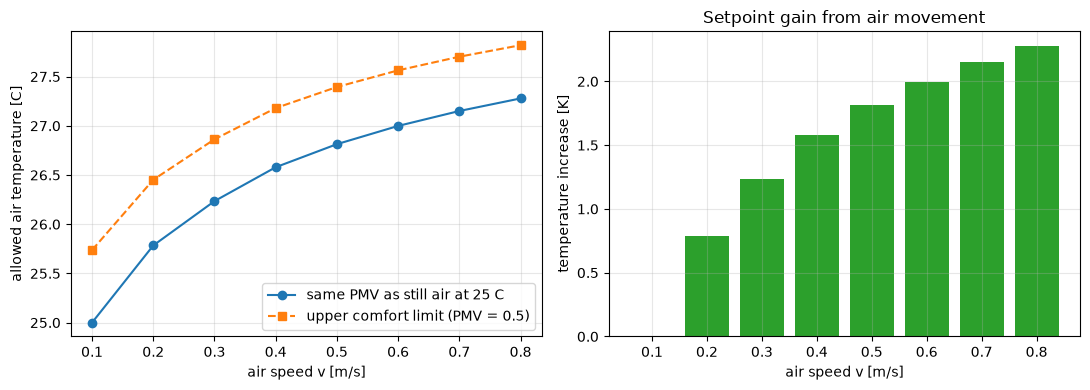

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(p1.v, p1.ta_same_pmv, "o-", label="same PMV as still air at 25 C")
ax[0].plot(p1.v, p1.ta_at_limit, "s--", label="upper comfort limit (PMV = 0.5)")
ax[0].set(xlabel="air speed v [m/s]", ylabel="allowed air temperature [C]"); ax[0].legend()
ax[1].bar(p1.v.astype(str), p1.gain, color="tab:green")
ax[1].set(xlabel="air speed v [m/s]", ylabel="temperature increase [K]", title="Setpoint gain from air movement")
plt.tight_layout(); plt.show()

### Interpretation of Part 1

* **Reference:** still air at 25 °C gives PMV = 0.278, so the room is already slightly on the warm side but inside Category II.
* **Gain:** raising $v$ from 0.1 to 0.8 m/s lets $t_a$ rise from 25 °C to about **27.3 °C**, an increase of **+2.3 K** at the same PMV. The upper comfort limit moves from 25.7 °C to 27.8 °C.
* **Diminishing returns:** the first step (0.1 to 0.2 m/s) buys **+0.8 K**, while the last step (0.7 to 0.8) buys only **+0.13 K**. The curve is concave because the cooling effect of moving air on skin and clothing saturates. This is why ceiling fans are run at moderate speed (0.3 to 0.6 m/s); above that, papers start to fly and the extra gain is small.
* **Energy meaning:** with the 6 to 10 % per °C rule, +2 K of cooling setpoint is roughly **12 to 20 % less cooling energy**, paid for by a fan that uses a few tens of watts. That justifies the **passive / hybrid cooling strategy**: fans first, compressor only when the fan alone is not enough.
* **Last column:** if the setpoint stays at 25 °C and we add airflow, the PMV falls well below the reference value. That means we would be *over-cooling* and wasting energy.

# Part 2: Dynamic data processing with pandas

**Task.** The file `date_cladire_24h.csv` has 24 hourly rows of $t_a$, $t_{mr}$ and RH on a spring/autumn transition day. Apply the PMV function to every row and find the hours where the building leaves the comfort zone **without HVAC**.

**Assumptions** (the sheet does not fix them): light indoor clothing for a transition day **clo = 0.7**, seated office work **met = 1.2**, no fan, still indoor air **v = 0.1 m/s**.

In [5]:
day = free_running_day(load_day(CSV))        # clo 0.7, met 1.2, v 0.1 m/s
day.round(2)

,hour,ta,tmr,rh,pmv,ppd,t_o,status
0,0,20.5,21.6,62.5,-0.52,10.55,21.05,too cold
1,1,20.1,21.1,65.6,-0.62,13.05,20.60,too cold
2,2,20.0,20.5,68.0,-0.69,15.02,20.25,too cold
3,3,20.1,21.2,69.5,-0.59,12.24,20.65,too cold
4,4,20.5,20.3,70.0,-0.62,13.10,20.40,too cold
5,5,21.2,21.5,69.5,-0.38,8.00,21.35,ok
6,6,22.0,22.0,68.0,-0.21,5.94,22.00,ok
7,7,23.0,22.7,65.6,0.00,5.00,22.85,ok
8,8,24.0,24.4,62.5,0.33,7.29,24.20,ok
9,9,25.0,25.3,58.9,0.56,11.60,25.15,too warm


too cold: [0, 1, 2, 3, 4]
too warm: [9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
Comfortable 9 of 24 h; worst PMV 1.35 at hour 13, coldest PMV -0.69 at hour 2


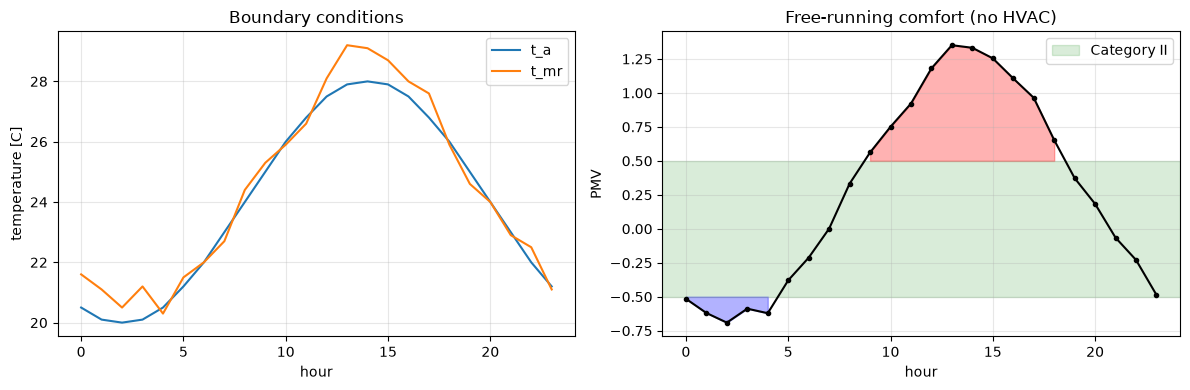

In [6]:
cold, warm = hours_outside(day)
print("too cold:", cold)
print("too warm:", warm)
print(f"Comfortable {24 - len(cold) - len(warm)} of 24 h; worst PMV {day.pmv.max():.2f} at hour {day.hour[day.pmv.idxmax()]}, "
      f"coldest PMV {day.pmv.min():.2f} at hour {day.hour[day.pmv.idxmin()]}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(day.hour, day.ta, label="t_a"); ax[0].plot(day.hour, day.tmr, label="t_mr")
ax[0].set(xlabel="hour", ylabel="temperature [C]", title="Boundary conditions"); ax[0].legend()
ax[1].plot(day.hour, day.pmv, "k.-"); ax[1].axhspan(-0.5, 0.5, color="green", alpha=.15, label="Category II")
ax[1].fill_between(day.hour, day.pmv, 0.5, where=day.pmv >= 0.5, color="red", alpha=.3)
ax[1].fill_between(day.hour, day.pmv, -0.5, where=day.pmv <= -0.5, color="blue", alpha=.3)
ax[1].set(xlabel="hour", ylabel="PMV", title="Free-running comfort (no HVAC)"); ax[1].legend()
plt.tight_layout(); plt.show()

In [7]:
# how sensitive is the answer to the clothing assumption?
raw = load_day(CSV)
for clo in (0.5, 0.7, 1.0):
    c, w = hours_outside(free_running_day(raw, clo=clo))
    print(f"clo={clo}: {len(c) + len(w):2d} h outside -> too cold {c}, too warm {w}")

clo=0.5: 16 h outside -> too cold [0, 1, 2, 3, 4, 5, 6, 22, 23], too warm [11, 12, 13, 14, 15, 16, 17]
clo=0.7: 15 h outside -> too cold [0, 1, 2, 3, 4], too warm [9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
clo=1.0: 13 h outside -> too cold [], too warm [8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]


### Interpretation of Part 2

* **Result (clo = 0.7):** 15 of 24 hours are outside Category II, so the building is comfortable only **9 h/day** by itself.
* **Two separate problems, one per time of day:**
  * **Night and early morning, hours 0 to 4** (PMV -0.52 to -0.69): the air is 20 to 20.5 °C and RH is high (62 to 70 %). The room is *slightly cool*; PPD reaches 15 % at hour 2, which is the coldest point (air 20.0 °C, $t_{mr}$ 20.5 °C).
  * **Late morning to evening, hours 9 to 18** (PMV 0.56 up to **1.35** at hour 13): the afternoon sun heats the air to 28 °C and the surfaces even more ($t_{mr}$ = 29.2 °C at hour 13, above $t_a$). PPD reaches **43 %**, so almost half of the occupants would complain.
* **Comfort window:** hours 5 to 8 and 19 to 23 are fine. Hour 7 has PMV = 0.00 (ideal, PPD = 5 %). In these hours **no HVAC is needed**, and the control system should switch off.
* **Mean radiant temperature matters:** in the afternoon $t_{mr} > t_a$ (solar gain on walls and glass), so the room feels hotter than the thermometer says. A thermostat on $t_a$ alone would under-react. In the early morning $t_{mr}$ is close to $t_a$ and the two agree.
* **Heating or cooling?** The day needs *both*: a little heating for hours 0 to 4 and cooling (or fans, see Part 1) for hours 9 to 18. This is typical of transition seasons and is why simple seasonal on/off logic wastes energy.
* **Sensitivity to clothing:** with clo = 0.5 the cold hours widen (0 to 6, 22, 23) and the warm hours shrink (11 to 17); with clo = 1.0 the cold hours disappear but hours 8 to 20 become too warm. The assumption about the occupants changes the answer, so a smart system should know or estimate clothing (for example from the season or the outdoor temperature of the last days).

# Part 3: Optimizing the HVAC setpoint (basis for AI)

**Scenario.** Extreme winter. Cold windows and walls make $t_{mr}$ low, and the HVAC controls only $t_a$. Write an optimization that returns the **lowest $t_a$ with PMV >= -0.5**, so the heating does no more than necessary.

**Assumptions.** Winter clothing clo = 1.0, met = 1.2, RH = 40 %, v = 0.1 m/s, and $t_{mr} = 17$ °C (about 4 K below a typical room, plausible next to a poorly insulated window).

PMV rises monotonically with $t_a$, so the lowest comfortable $t_a$ is the **root** of $PMV(t_a) = -0.5$. Two ways are shown: a `while` loop (what a simple controller would do) and `scipy.optimize.brentq`.

In [8]:
ta_while, steps = lowest_setpoint_while(17.0)     # simple controller: raise ta in 0.05 K steps
ta_root = lowest_setpoint(17.0)                   # root finder
print(f"while loop : ta_min = {ta_while:.2f} C after {steps} steps")
print(f"brentq     : ta_min = {ta_root:.3f} C")
print(f"PMV at ta_min = {pmv(ta_root, 17.0, 0.1, 40, 1.0):.3f}, PPD = {ppd(ta_root, 17.0, 0.1, 40, 1.0):.1f} %")
print(f"Saving versus the fixed 23 C standard: {23 - ta_root:.2f} K")

while loop : ta_min = 21.30 C after 226 steps
brentq     : ta_min = 21.265 C
PMV at ta_min = -0.500, PPD = 10.2 %
Saving versus the fixed 23 C standard: 1.74 K


,tmr,ta_min,ta_min_light,saving vs 23 C [K]
0,14.0,23.73,26.50,-0.73
1,15.0,22.92,25.69,0.08
2,16.0,22.10,24.87,0.90
3,17.0,21.26,24.04,1.74
4,18.0,20.42,23.19,2.58
5,19.0,19.56,22.33,3.44
6,20.0,18.70,21.46,4.30
7,21.0,17.97,20.58,5.03
8,22.0,17.26,19.79,5.74


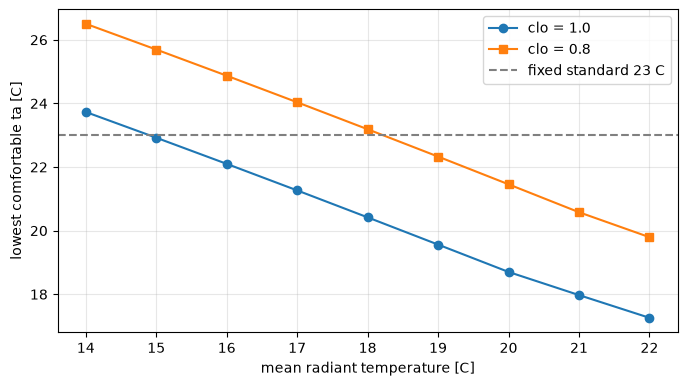

In [9]:
tab = setpoint_vs_tmr(np.arange(14, 22.1, 1.0))      # clo 1.0 and the lighter clo 0.8
tab["saving vs 23 C [K]"] = 23 - tab.ta_min
display(tab.round(2))

plt.plot(tab.tmr, tab.ta_min, "o-", label="clo = 1.0")
plt.plot(tab.tmr, tab.ta_min_light, "s-", label="clo = 0.8")
plt.axhline(23, color="gray", ls="--", label="fixed standard 23 C")
plt.xlabel("mean radiant temperature [C]"); plt.ylabel("lowest comfortable ta [C]"); plt.legend(); plt.show()

### Interpretation of Part 3

* **Result:** with $t_{mr}$ = 17 °C and clo = 1.0, the lowest comfortable air temperature is **about 21.3 °C**, with PMV = -0.50 and PPD about 10 %. This matches the sheet's example (21.3 °C instead of the fixed 23 °C). The while loop and `brentq` agree to within the loop step (0.05 K); `brentq` needs only a handful of PMV evaluations, the loop needed 226 steps.
* **Saving:** holding 21.3 °C instead of 23 °C is **-1.7 K**. With the 6 to 10 % per °C rule that is about **10 to 17 % less heating energy** for the same occupant satisfaction (PPD <= 10 %).
* **Radiant compensation:** each +1 K of $t_{mr}$ lets the air be about **0.8 K cooler** (the table drops from 23.7 °C at $t_{mr}$ = 14 to 18.0 °C at $t_{mr}$ = 21). The body reacts to both temperatures, and at low air speed the air still weighs slightly more than the surfaces. So **better windows or radiant heating can save more energy than a higher air setpoint.**
* **Clothing:** going from clo = 1.0 to 0.8 (a lighter sweater) raises the required air temperature by about 2.8 K at the same $t_{mr}$. Dressing for the season is a free "HVAC measure".
* **Why this is the basis for AI:** the function takes *measured conditions in* and returns a *setpoint out*, recomputed every few minutes. A smart controller (rule-based as here, or RL) just wraps this loop around live sensor data. The fixed 23 °C is a safe average that overheats whenever the walls are warm and underheats when they are very cold.
* **Limits:** the optimum sits exactly on the PMV = -0.5 boundary, so any sensor error pushes people into "slightly cool". A real controller keeps a small margin (for example target PMV = -0.4) and respects minimum ventilation and humidity requirements.

# Part 4: The same analysis for several seasons

The sheet fixes only some assumptions, so here we compute **the comfortable air-temperature band** and the **free-running day** for several seasonal presets at once. The presets live in `SEASONS` (in `hvac_setpoint.py`).

| Season | clo | met | RH | v | $t_{mr}$ |
|---|---|---|---|---|---|
| summer | 0.5 | 1.2 | 50 % | 0.1 | $t_a + 1$ (sunny walls) |
| autumn / spring | 0.7 | 1.2 | 50 % | 0.1 | $t_a$ |
| winter | 1.0 | 1.2 | 40 % | 0.1 | 17 °C (cold windows, sheet example) |
| winter, heavy clothing | 1.2 | 1.2 | 40 % | 0.1 | 16 °C (heavier clothing, colder walls) |

For each preset: lowest and highest $t_a$ with $-0.5 \le PMV \le 0.5$ (the **comfort band**), and how many hours of the CSV day would be outside comfort if people wore that clothing. Pass your own dictionary to `seasons_table(df, seasons=...)` to add a case.

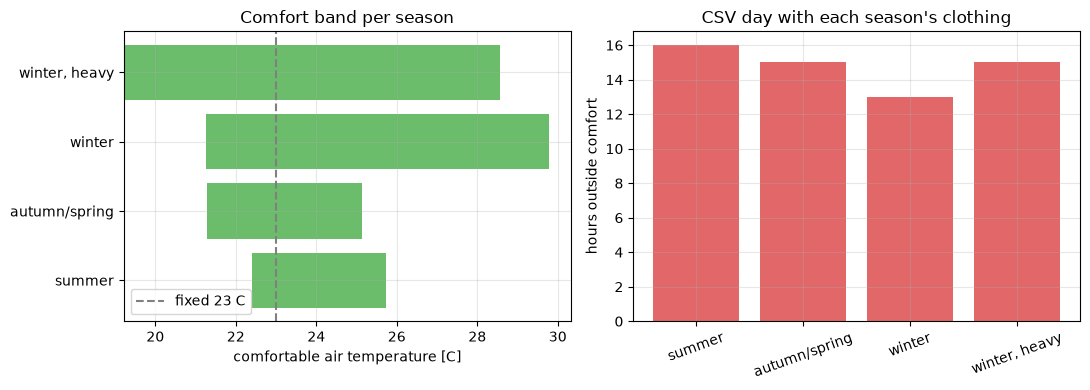

,season,ta_min,ta_max,width,hours_outside,pmv_min,pmv_max
0,summer,22.41,25.74,3.33,16,-1.23,1.16
1,autumn/spring,21.29,25.15,3.85,15,-0.69,1.35
2,winter,21.26,29.79,8.52,13,-0.16,1.54
3,"winter, heavy",19.21,28.57,9.36,15,0.12,1.66


In [10]:
p4 = seasons_table(load_day(CSV))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].barh(p4.season, p4.width, left=p4.ta_min, color="tab:green", alpha=.7)
ax[0].axvline(23, color="gray", ls="--", label="fixed 23 C"); ax[0].set(xlabel="comfortable air temperature [C]", title="Comfort band per season"); ax[0].legend()
ax[1].bar(p4.season, p4.hours_outside, color="tab:red", alpha=.7)
ax[1].set(ylabel="hours outside comfort", title="CSV day with each season's clothing"); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
p4.round(2)

### Interpretation of Part 4

* **The lower limit moves a lot with the season:** summer 22.4 °C, autumn/spring 21.3 °C, winter 21.3 °C (with 17 °C walls), winter with heavier clothing and colder walls 19.2 °C. So **one fixed setpoint cannot be right all year**; the cheapest comfortable value depends on clothing and wall temperature.
* **Summer has the narrowest band** (3.3 K, 22.4 to 25.7 °C): light clothing leaves little tolerance, and sunny surfaces ($t_{mr}=t_a+1$) make the room feel warmer. This is where fans (Part 1) help most, because they move the upper limit.
* **Winter bands are wide (8.5 and 9.4 K) only on paper.** The upper limits (29.8 and 28.6 °C) assume the walls stay at 17 or 16 °C while the air is hot, which never happens in practice. Read the winter row for its **lower limit**, the quantity the heating controller needs.
* **Clothing is the biggest lever:** clo 1.2 instead of 1.0 lowers the minimum air temperature by 2 K, but with 1 K colder walls. Both winter cases are valid; the difference is only the assumptions, so a report should always state them.
* **Free-running CSV day:** 16 h outside comfort with summer clothing, 15 h with autumn clothing, 13 h with winter clothing (15 h for the heavy winter case, clo 1.2). With heavy clothing the cold hours vanish but the afternoon becomes too warm. Autumn clothing (clo 0.7) is the best fit for this mild transition day, and it still fails 15 h, so this building needs active control in either direction.

# Summary of the four parts

| Part | Main number | Meaning |
|---|---|---|
| 1 | +2.3 K at 0.8 m/s | air movement allows a warmer cooling setpoint, with diminishing returns |
| 2 | 15 of 24 h uncomfortable | night slightly cold, afternoon hot (PMV up to 1.35, PPD 43 %), $t_{mr}$ matters |
| 3 | 21.3 °C vs 23 °C | optimizer saves about 1.7 K of heating setpoint at the comfort limit |
| 4 | band 3.3 K (summer) to 8.5 K (winter) | the comfortable air temperature depends on the season, clothing and wall temperature |